In [1]:
import numpy as np
import FBA_ode

In [2]:
# constants
k = np.zeros(31)

k[0] = 1.0e-5  # Permeability constant (plasma membrane) (cm/s)
k[1] = 1.1e-7  # Intracellular peroxide production (M/s)
k[2] = 2.1e7  # GPx_red reacting with H2O2in (M-1*s-1)
k[3] = 4e4  # GPx_ox reacting with GSH (M-1*s-1)
k[4] = 1e7  # GPx-SSG reacting with GSH (M-1*s-1)
k[5] = 3.4e7  # Catalase reacts with H2O2 inside peroxisome (M-1*s-1)
k[6] = 5.7e-5  # Km of NADP+ (M)
k[7] = 4e7  # Peroxiredoxin is oxidized by H2O2 (M-1*s-1)
k[8] = 7.2e4  # Oxidized peroxiredoxin is over-oxidized by H2O2 (M-1*s-1)
k[9] = 3e-3  # Reduction of overoxidized Prx by Srx enzyme (s-1)
k[10] = 15  # Self-catalyzed disulfide formation of Prx-SS from Prx-SOH (s-1)
k[11] = 2.1e6  # Peroxiredoxin is reduced by Thioredoxin (M-1*s-1)
k[12] = 7.4e-05  # Auto-oxidation of GSH (s-1)
k[13] = 1e4  # Protein monothiol oxidized by H2O2 (M-1*s-1)
k[14] = 1.2e5  # Oxidized Protein monothiol glutathionylated by GSH (M-1*s-1)
k[15] = 9.1e4  # Grx-SH de-glutathionylates Protein-SSG (M-1*s-1)
k[16] = 3.7e4  # GSH de-glutathionylates Grx-SSG (M-1*s-1)
k[17] = 5e5  # Protein dithiol oxidized by H2O2 (M-1*s-1)
k[18] = 1e5  # Protein disulfide reduced by Trx (M-1*s-1)
k[19] = 3.2e6  # GSSG reduced by GR (M-1*s-1)
k[20] = 2e7  # Oxidized Thioredoxin reduced by TrxR (M-1*s-1)
k[21] = 3.75e-04  # Production of NADPH by G6P-DH (M/s)
k[22] = 3e-3  # Permeability constant (peroxisomal membrane) (cm/s)
k[23] = 4.1e-7  # GSH synthesis (M/s)
k[24] = 1.2e-8  # GSSG efflux (M/s)
k[25] = 1.2e-7  # GSH + GSSG efflux (M/s)
k[26] = 7.45e-10  # Trx_SH efflux (M/s)
k[27] = 6.97e-10  # Trx_SH synthesis (M/s)
k[28] = 1e-7 # nox generation of superoxide ()
k[29] = 4e9 # superoxide dismutase reduction and oxidation by superoxide (M-1*s-1)
k[30] = 1e-4 # intracellular superoxide production (M/s)

print(k)

[1.00e-05 1.10e-07 2.10e+07 4.00e+04 1.00e+07 3.40e+07 5.70e-05 4.00e+07
 7.20e+04 3.00e-03 1.50e+01 2.10e+06 7.40e-05 1.00e+04 1.20e+05 9.10e+04
 3.70e+04 5.00e+05 1.00e+05 3.20e+06 2.00e+07 3.75e-04 3.00e-03 4.10e-07
 1.20e-08 1.20e-07 7.45e-10 6.97e-10 1.00e-07 4.00e+09 1.00e-04]


In [3]:
# initial conditions

# % Defining initial Conditions (Concentrations in uM = uMoles/Liter)
# % Defining the array, x0, that will house initial concentrations
x0 = np.zeros(28)  # Defining the array, x0, that will house initial concentrations
# Cytoplasm
x0[0] = 1e-4  # H2O2media 
x0[1] = 1.0e-9  # H2O2cytosol

x0[2] = 5e-5  # GPXr 
x0[3] = 1e-14  # GPXo 
x0[4] = 1e-14  # GPX-SG 

x0[5] = 3.68e-4  # GSH 
x0[6] = 1.78e-6  # GSSG 

x0[7] = 9e-7  # Catalase 
x0[8] = 1.0e-10  # H2O2peroxisome 

x0[9] = 1.92e-5  # Prx-SH  
x0[10] = 1e-14  # Prx-SOH 
x0[11] = 1e-14  # Prx-SOOH 
x0[12] = x0[9] * (0.5 / 100)  # Prx-SS 

x0[13] = 4.27e-7  # Trx1-SH 
x0[14] = 7.54e-8  # Trx1-SS 

x0[15] = 1.22e-4  # Pr-SH 
x0[16] = x0[15] * (0.5 / 100)  # Pr-SOH
x0[17] = x0[15] * (0.5 / 100)  # Pr-SSG 

x0[18] = 1.20e-6  # Grx-SH 
x0[19] = x0[18] * (0.5 / 100)  # Grx-SSG 

x0[20] = 1.09e-3  # Pr-(SH)2  
x0[21] = x0[20] * (0.5 / 100)  # Pr-SS

x0[22] = 3.0e-5  # NADPH 
x0[23] = 3.0e-7  # NADP+

x0[24] = 0 # superoxide media
x0[25] = 0 # superoxide cytosol

x0[26] = 1e-14 # superoxide dismutase reduced
x0[27] = 2e-5 # superoxide dismutase oxidized

In [4]:
import numpy as np
from scipy.integrate import odeint

def model(x, t, k):
    dxdt = np.zeros_like(x)
    dxdt[0] = k[0] * (x[1] - x[0]) * 10e-3 * 1.02e-5 * (1e9)

    dxdt[1] = (((k[0] * x[0] * 10e-3 * 1.02e-5) / (9.16e-13))
               - ((k[0] * x[1] * 10e-3 * 1.02e-5) / (9.16e-13))
               - 2 * (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14)
               - k[2] * x[2] * (x[1] - x0[1])
               - k[5] * x[7] * (x[1] - x0[1])
               - k[7] * x[9] * (x[1] - x0[1])
               - k[8] * x[10] * (x[1] - x0[1])
               - k[13] * x[15] * (x[1] - x0[1])
               - k[17] * x[20] * (x[1] - x0[1])
               + k[1]
               + k[29] * x[25] * x[27]                                      # superoxide dismutase reduction and oxidation by superoxide
               )
    
    dxdt[2] = - k[2] * x[2] * (x[1] - x0[1]) + k[4] * (x[4] - x0[4]) * x[5]
    dxdt[3] = k[2] * x[2] * (x[1] - x0[1]) - k[3] * (x[3] - x0[3]) * x[5]
    dxdt[4] = k[3] * (x[3] - x0[3]) * x[5] - k[4] * (x[4] - x0[4]) * x[5]
    dxdt[5] = (- k[3] * (x[3] - x0[3]) * x[5]
               - k[4] * (x[4] - x0[4]) * x[5]
               - 2 * k[12] * x[5]
               - k[14] * (x[16] - x0[16]) * x[5]
               - k[16] * (x[19] - x0[19]) * x[5]
               + 2 * k[19] * (x[6] - x0[6]) * x[22]
               + k[23] - k[25])
    dxdt[6] = (k[4] * (x[4] - x0[4]) * x[5] + k[12] * x[5] +
               k[16] * (x[19] - x0[19]) * x[5] - k[19] * (x[6] - x0[6]) * x[22] -
               k[24] - k[25])
    dxdt[7] = 0
    dxdt[8] = (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14) - k[5] * x[7] * (x[8] - x0[8])
    dxdt[9] = - k[7] * x[9] * (x[1] - x0[1]) + k[11] * (x[12] - x0[12]) * x[13]
    dxdt[10] = (k[7] * x[9] * (x[1] - x0[1]) - k[8] * x[10] * (x[1] - x0[1]) +
                k[9] * (x[11] - x0[11]) - k[10] * x[10])
    dxdt[11] = k[8] * x[10] * (x[1] - x0[1]) - k[9] * (x[11] - x0[11])
    dxdt[12] = k[10] * x[10] - k[11] * (x[12] - x0[12]) * x[13]
    dxdt[13] = (- k[11] * (x[12] - x0[12]) * x[13] 
                - k[18] * (x[21] - x0[21]) * x[13] 
                + k[20] * (x[14] - x0[14]) * x[22] 
                - k[26] 
                + k[27])
    dxdt[14] = (k[11] * (x[12] - x0[12]) * x[13] + k[18] * (x[21] - x0[21]) * x[13] -
                k[20] * (x[14] - x0[14]) * x[22])
    
    dxdt[15] = (- k[13] * x[15] * (x[1] - x0[1]) 
                + k[15] * x[18] * (x[17] - x0[17]))
    
    dxdt[16] = k[13] * x[15] * (x[1] - x0[1]) - k[14] * (x[16] - x0[16]) * x[5]
    dxdt[17] = k[14] * (x[16] - x0[16]) * x[5] - k[15] * x[18] * (x[17] - x0[17])
    dxdt[18] = k[16] * (x[19] - x0[19]) * x[5] - k[15] * x[18] * (x[17] - x0[17])
    dxdt[19] = k[15] * x[18] * (x[17] - x0[17]) - k[16] * (x[19] - x0[19]) * x[5]
    dxdt[20] = - k[17] * x[20] * (x[1] - x0[1]) + k[18] * (x[21] - x0[21]) * x[13]
    dxdt[21] = k[17] * x[20] * (x[1] - x0[1]) - k[18] * (x[21] - x0[21]) * x[13]

    dxdt[22] = (- k[19] * (x[6] - x0[6]) * x[22] 
                - k[20] * (x[14] - x0[14]) * x[22] 
                - k[28] * x[22]                                         # nox generation of superoxide
                + k[21] * (x[23] - x0[23]) / (k[6] + x[23]))
    
    dxdt[23] = (k[19] * (x[6] - x0[6]) * x[22] 
                + k[20] * (x[14] - x0[14]) * x[22] 
                + k[28] * x[22]                                         # nox generation of superoxide and nadp+
                - k[21] * (x[23] - x0[23]) / (k[6] + x[23]))
    
    dxdt[24] = (k[0] * (x[25] - x[24]) * 10e-3 * 1.02e-5 * (1e9)               # superoxide media
                + k[28] * x[22])
    
    dxdt[25] = (((k[0] * x[24] * 10e-3 * 1.02e-5) / (9.16e-13))                 # superoxide cytosol
               - ((k[0] * x[25] * 10e-3 * 1.02e-5) / (9.16e-13))
               - k[29] * x[25] * x[26]
               - k[29] * x[25] * x[27]
               + k[30])
    
    dxdt[26] = (k[29] * x[25] * x[27] 
                - k[29] * x[25] * x[26])

    dxdt[27] = (k[29] * x[25] * x[26] 
                - k[29] * x[25] * x[27])

    return dxdt


6.074952908055747e-10
6.298686625698292e-10


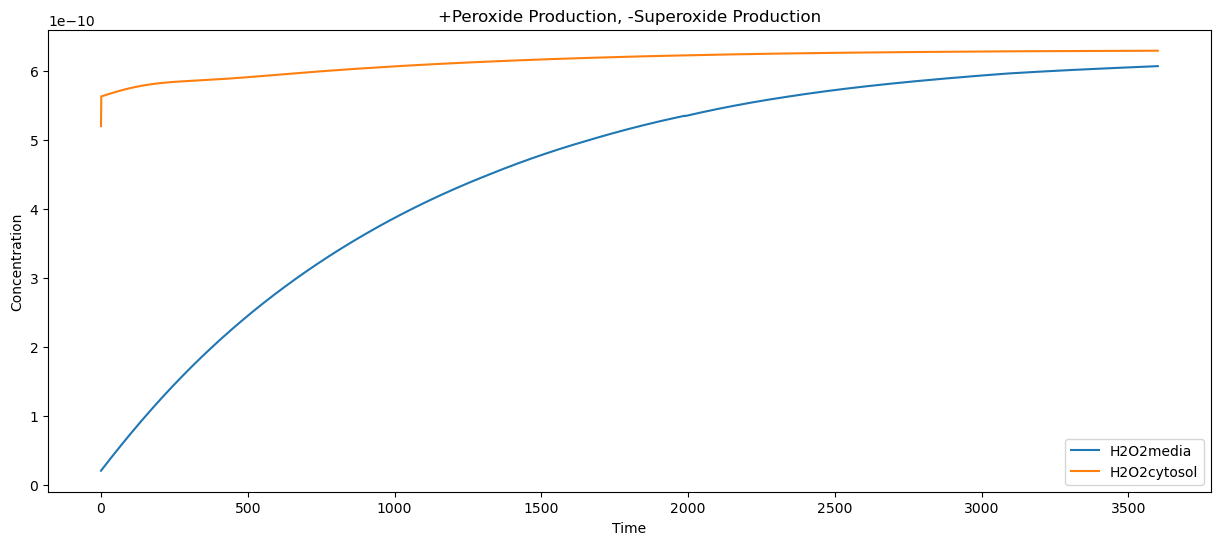

In [9]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

x0[0] = 2.019262743538677e-11 # H2O2media
x0[1] = 5.204363434194223e-10 # H2O2cytosol
#k[1] = 0 # intracellular peroxide production
k[28] = 1e-5 # nox generation of superoxide
#k[29] = 0 # superoxide dismutase reduction and oxidation by superoxide
k[30] = 0 # intracellular superoxide production

t = np.linspace(0, 3600, 3601)
solution = odeint(model, x0, t, args=(k,))

# Replace odeint with solve_ivp
# solution = solve_ivp(lambda t, y: model(y, t, k), 
#                     [0, 120000], 
#                     x0, 
#                     method='Radau',  # Use Backward Differentiation Formula (good for stiff problems)
#                     t_eval=np.linspace(0, 120000, 10000))

# Plot the results
plt.figure(figsize=(15, 6))
# for i in range(0, len(x0)): 
#     plt.plot(t, solution[:, i], label=f'x[{i}]')
# plt.plot(solution.t, solution.y[0, :], label='H2O2media')
# plt.plot(solution.t, solution.y[1, :], label='H2O2cytosol')
# plt.plot(solution.t, solution.y[24, :], label='superoxide media')
# plt.plot(solution.t, solution.y[25, :], label='superoxide cytosol')
# plt.plot(solution.t, solution.y[26, :], label='SOD reduced')
# plt.plot(solution.t, solution.y[27, :], label='SOD oxidized')

plt.plot(t, solution[:, 0], label='H2O2media')
plt.plot(t, solution[:, 1], label='H2O2cytosol')
# plt.plot(t, solution[:, 22], label='NADPH')
# plt.plot(t, solution[:, 23], label='NADP-')
# plt.plot(t, solution[:, 26], label='SOD reduced')
# plt.plot(t, solution[:, 27], label='SOD oxidized')
print(solution[-1, 0])
print(solution[-1, 1])

plt.xlabel('Time')
plt.ylabel('Concentration')
plt.title('+Peroxide Production, -Superoxide Production')
plt.legend()
plt.show()

Completed 0 of 3600 steps
Completed 360 of 3600 steps
Completed 720 of 3600 steps
Completed 1080 of 3600 steps
Completed 1440 of 3600 steps
Completed 1800 of 3600 steps
Completed 2160 of 3600 steps
Completed 2520 of 3600 steps
Completed 2880 of 3600 steps
Completed 3240 of 3600 steps


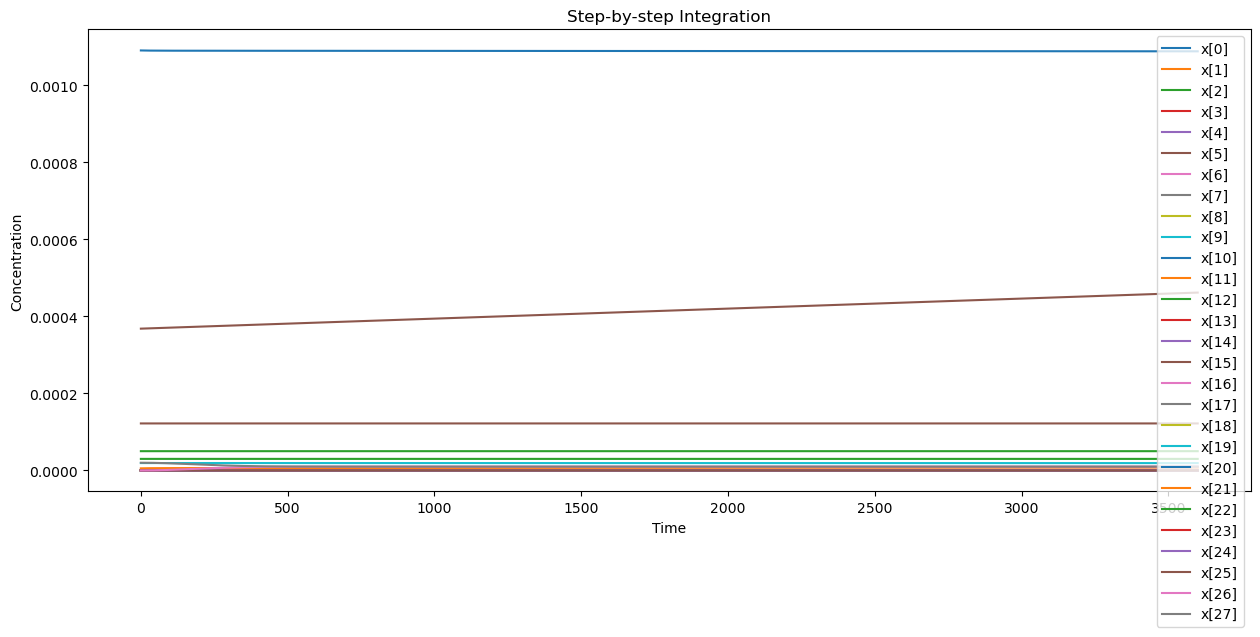

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Setup
num_steps = 3600
dt = 1  # 1 second per step
t_span = [0, dt]  # Integration span for each step
t_full = np.linspace(0, num_steps, num_steps+1)
x_current = x0.copy()  # Start with initial conditions

# Storage for results
solution = np.zeros((num_steps+1, len(x0)))
solution[0, :] = x0  # Store initial conditions

# Step-by-step integration
for i in range(num_steps):
    # Integrate just one time step
    t_local = np.array([0, dt])
    x_step = odeint(model, x_current, t_local, args=(k,))
    
    # Update current state (take the final state from this step)
    x_current = x_step[-1, :].copy()
    
    # Store results
    solution[i+1, :] = x_current
    
    # Here you could modify x_current if needed
    # For example: x_current[0] += some_input_function(i)
    
    # Optional: Print progress occasionally
    if i % 360 == 0:
        print(f"Completed {i} of {num_steps} steps")

# Then plot as before
plt.figure(figsize=(15, 6))
for i in range(0, len(x0)):
    plt.plot(t_full, solution[:, i], label=f'x[{i}]')
plt.xlabel('Time')
plt.ylabel('Concentration')
plt.title('Step-by-step Integration')
plt.legend()
plt.show()